In [31]:
import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt

In [32]:

def choosecolor (valorhsv):
    #sobre 2 menos 1
    vermelho = 2#5
    amarelo = 32#66
    verde = 79#160
    azul = 96#193
    h = int(valorhsv[0])

    dist = [0,0,0,0]

    # print("aaaa")

    dist[0] = abs(h - vermelho)
    dist[1] = abs(h - amarelo)
    dist[2] = abs(h - verde)
    dist[3] = abs(h - azul)

    # print("bbbb")

    a = min(dist)
    # print(dist)

    return dist.index(a)






def getcolor (img, c1):

    # for c in circulos[0, :]:

    c = (int(c1[0]),int(c1[1]),int(c1[2]))

    r = int(c[2])
    hues = [0,0,0,0]
    # print(img.shape)

    for i in range(-1*r, r):
        for j in range(-1*r, r):
            if (c[0] + i < 0 or c[0] + i >= img.shape[0] or c[1] + j < 0 or c[1] + j >= img.shape[1]):
                continue
            dist = np.sqrt((i)**2 + (j)**2)
            # print("cheguei aqui 3 e a dist eh igual a " + str(dist))
            if int(dist) <= r and int(dist) >= r*2/3 : # ta dentro da area
                if (img[c[0] + i][c[1] + j][1] > 15): # se eh suficientemente longe do gray
                    # print(img[c[0] + i][c[1] + j])
                    # print(c[0] + i)
                    # print(c[1] + j)
                    hues[choosecolor(img[c[0] + i][c[1] + j])]+=1
    # print(hues)
    # print(hues)
                    
    return hues.index(max(hues))

                


    # for i in circulos[0, :]:
    # cv.circle(imgfinal, (i[0], i[1]), i[2], (0, 255, 0), 1)

    # cv.circle(imgfinal, (i[0], i[1]), int(np.around(2*i[2]/3)), (0, 255, 0), 1)

    # cv.circle(imgfinal, (i[0],i[1]), 2, (0, 0, 255), 3)

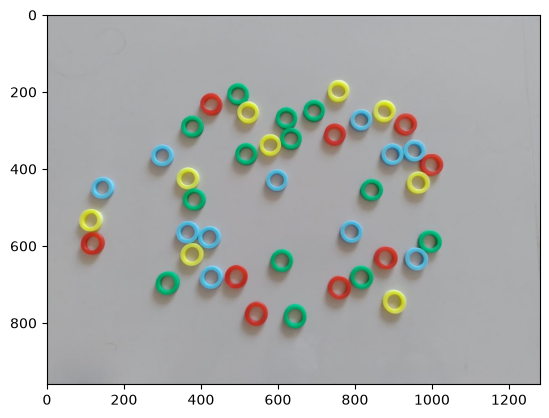

In [33]:
filepath = "../img/1.jpg"
img = cv.imread(filepath)
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)
imghsv = cv.cvtColor(img, cv.COLOR_RGB2HSV)
# hue vai nos ajudar mais do que rgb!
imgray = cv.cvtColor(img, cv.COLOR_RGB2GRAY)
plt.imshow(img)
imgray = cv.GaussianBlur(imgray, (7, 7), 1.5)

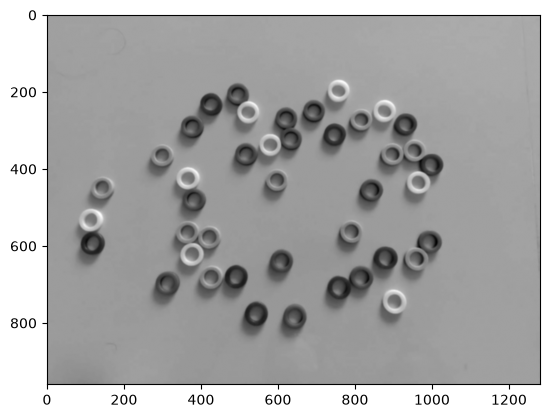

In [34]:
plt.imshow(imgray, cmap='gray')

In [35]:
circulos = cv.HoughCircles(imgray, cv.HOUGH_GRADIENT, 1, 20, param1=50, param2=30, minRadius=10, maxRadius=40)
circulosinternos = cv.HoughCircles(imgray, cv.HOUGH_GRADIENT,20, 20, param1=50, param2=50, minRadius=15, maxRadius=25)


In [36]:
circulos = np.uint16(np.around(circulos))
print(circulos.shape)
# circulosinternos = np.uint16(np.around(circulosinternos))
# print(circulosinternos.shape)

imgfinal = img

# imgfinalinternos = img.copy()

cores = [0,0,0,0]

for i in circulos[0, :]:
    a = getcolor(img, i)
    cor = (0,0,0)
    s = "a cor selecionada foi: "
    match a:
        case 0:
            cor = (2, 120, 255)
            cores[0]+=1
        case 1:
            cor = (32, 120, 255)
            cores[1]+=1
            # print(s + "amarelo")
        case 2:
            cor = (79, 120, 255)
            cores[2]+=1
            # print(s + "verde")
        case 3:
            cor = (96, 120, 255)
            cores[3]+=1
            # print(s + "azul")
        
    cv.circle(imgfinal, (i[0], i[1]), i[2], cor, 1)

    cv.circle(imgfinal, (i[0], i[1]), int(np.around(2*i[2]/3)), cor, 1)

    cv.circle(imgfinal, (i[0],i[1]), 2, cor, 3)
    

# for i in circulosinternos[0, :]:
#     cv.circle(imgfinalinternos, (i[0], i[1]), i[2], (0, 255, 0), 1)

#     cv.circle(imgfinalinternos, (i[0],i[1]), 2, (0, 0, 255), 3)
print(cores)

(1, 42, 3)


[2, 0, 0, 40]


In [37]:
# print(circulos)

In [38]:
# print(circulosinternos)

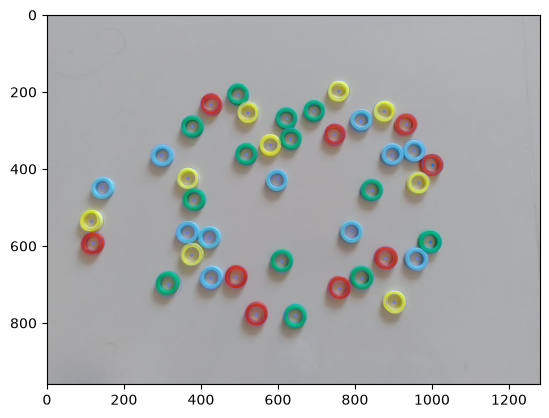

In [39]:
plt.imshow(imgfinal)

In [40]:
# plt.imshow(imgfinalinternos)
print(imghsv[0][0])

[110   4 174]


ok entao temos os centros, os raios possivelmente errados e a imagem em hsv

no entanto! temos que a proporcao entre o raio interno e externo eh constante

posso pegar a moda de todos os pixels? vai ser O(t*40^2)